# Лабораторная работа №1: регрессия (Wine Quality)

**Задача:** по физико-химическим признакам вина предсказать его оценку `quality` (от 3 до 9).
**Метрики:** основная — RMSE (порог < 0.70), дополнительная — MAE.

## 0. Импорты

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42

## 1. Загрузка данных

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")

red["is_red"] = 1
white["is_red"] = 0

# склеиваем таблицы друг под другом, нумерация строк заново
df = pd.concat([red, white], ignore_index=True)
df.shape

(6497, 13)

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [5]:
print("Пропусков всего:", df.isna().sum().sum())
print(f"Дубликатов: {df.duplicated().sum()}")

Пропусков всего: 0
Дубликатов: 1177


In [6]:
# reset_index(drop=True) заново нумерует строки
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(5320, 13)

## 2. Первичный анализ данных (EDA)

.T транспонирование

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


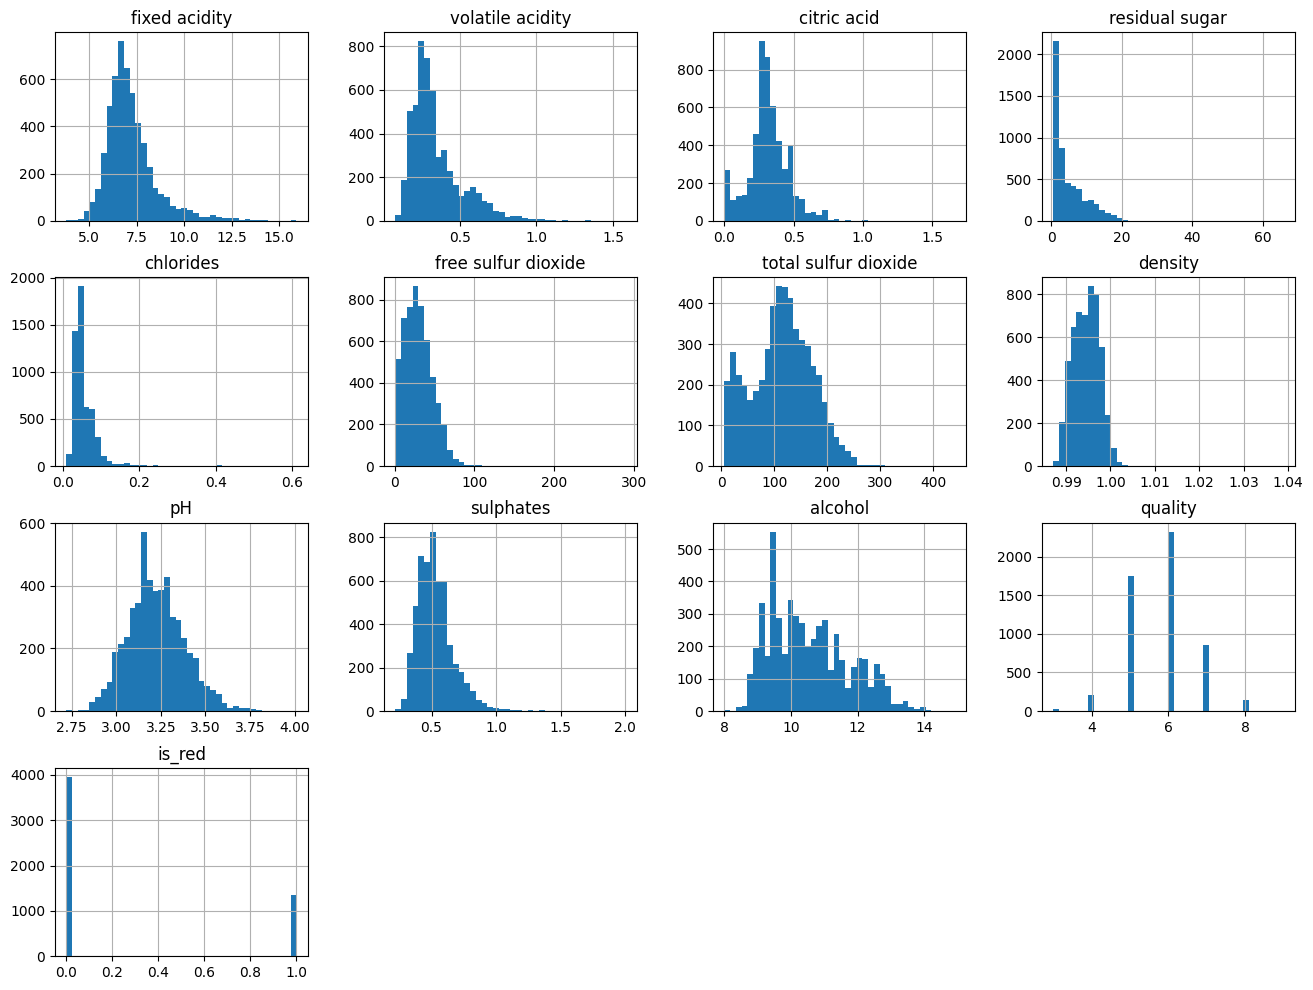

In [24]:
# нарисовать гистограмму для кажд столбца
# знач распред в 40 групп 
df.hist(bins=40, figsize=(16, 12))
# раздвинуть графики, чтобы подписи не налезали друг на друга
# plt.tight_layout()
plt.show()

**Вывод.** Есть выбросы.

Выбросы сильнее мешают **линейной регрессии**: одна точка с огромным значением умножается на вес и «перетягивает» прямую. **Деревьям** выбросы почти не мешают — они задают вопросы «больше/меньше порога», и им важен только порядок значений, а не их величина

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


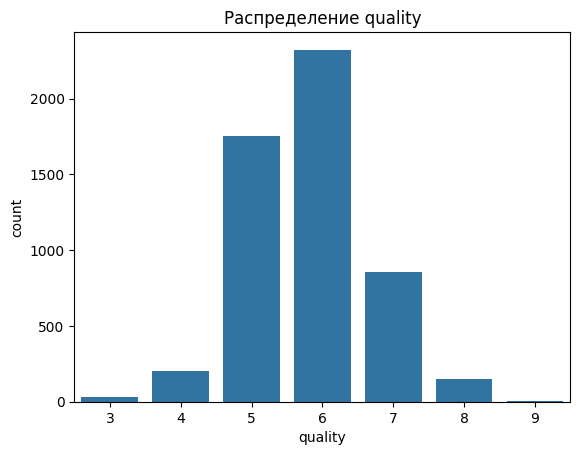

In [25]:
print(df["quality"].value_counts().sort_index())
# рисуем столбики кол-во вин и оуенка 
# по гориз quality данные из df
sns.countplot(x="quality", data=df) 
plt.title("Распределение quality")
plt.show()

**Вывод.** Классы несбалансированы: почти все вина имеют оценку 5 или 6 (1752 и 2323 из 5320), а крайних оценок очень мало: 30 вин с оценкой 3 и всего 5 с оценкой 9.

Ожидаем, что модель хорошо научится предсказывать 5 и 6, а на редких оценках будет ошибаться сильнее и тянуть прогнозы к середине.

In [26]:
# корреляция quality с другими по возраст 
df.corr()["quality"].sort_values() 

density                -0.326434
volatile acidity       -0.265205
chlorides              -0.202137
is_red                 -0.114809
fixed acidity          -0.080092
residual sugar         -0.056830
total sulfur dioxide   -0.050296
pH                      0.039733
sulphates               0.041884
free sulfur dioxide     0.054002
citric acid             0.097954
alcohol                 0.469422
quality                 1.000000
Name: quality, dtype: float64

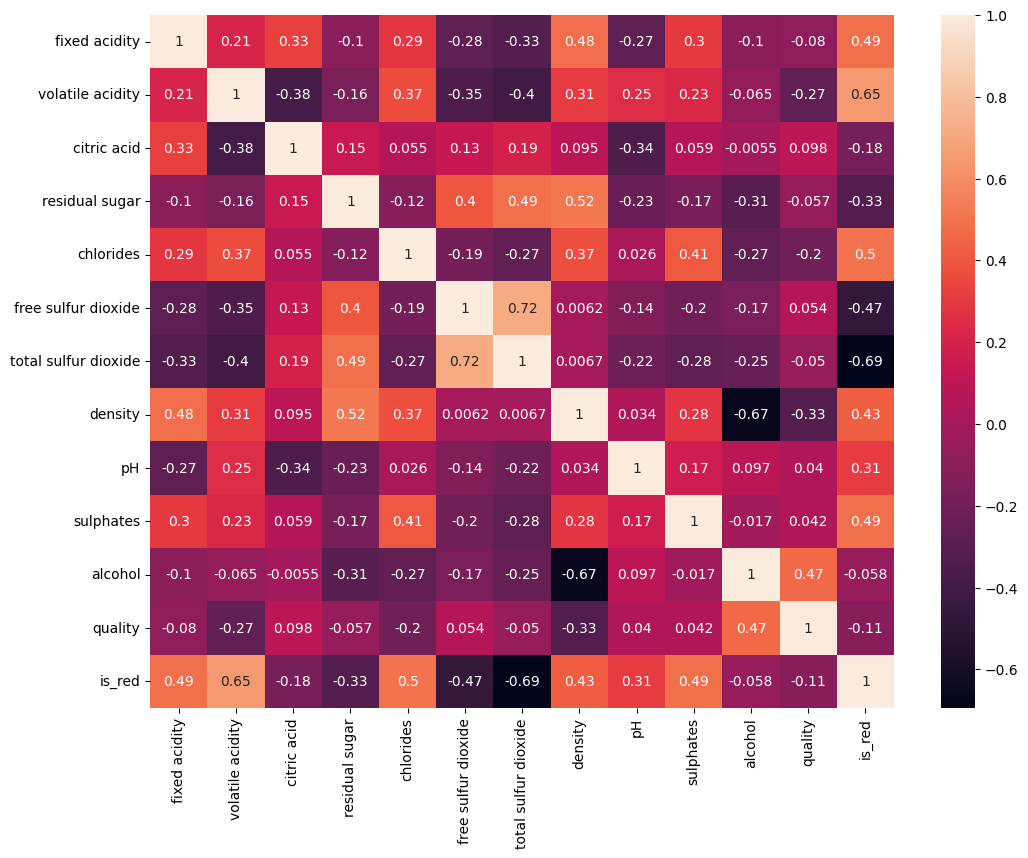

In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True)
plt.show()

**Вывод.** Сильнее всего с качеством связан **alcohol** (корреляция +0.47): более крепкие вина в среднем получают более высокую оценку.

Между собой некоторые признаки сильно связаны (**мультиколлинеарность**): `density` и `alcohol` (−0.69), `free` и `total sulfur dioxide` (+0.72), `density` и `residual sugar` (+0.55), а также `is_red` с несколькими признаками (красные и белые сильно различаются по составу). Такие признаки несут похожую информацию. Это помешает интерпретации: коэффициенты линейной регрессии для них могут стать нестабильными, а важность в деревьях — делиться между ними.


## 3. Разбиение на train и test

In [ ]:
X = df.drop(columns="quality") # таблица признаков
y = df["quality"] # оценки

# random_state=RANDOM_STATE фиксируем случайность 
# с фиксированным random_state при каждом запуске в тест попадут 
# одни и те же вина и результаты повторятся
# stratify=y длеаем так чтобы одинак доли оценок попали и в трэин и в тест чтобы не 
# что где-то больше 
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, 
    random_state=RANDOM_STATE,
    stratify=y,
)

print(X_train.shape, X_test.shape)


(4256, 12) (1064, 12)


- **Размер выборок:** 80% train (4256 вин) и 20% test (1064 вина).
- **Способ разбиения:** случайное разбиение со стратификацией по `quality` (`stratify=y`) — из-за несбалансированного таргета, чтобы доли каждой оценки были одинаковы в train и test. `random_state` зафиксирован, чтобы эксперимент воспроизводился.
- **Проблема многократной оценки на одном тесте:** если много раз менять модель, тест перестаёт быть новыми данными, а новых данных модель покажет себя хуже. 

## 4. Метрики и baseline

In [13]:
def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae

results = []
baseline_value = y_train.mean()
# массив длиной как тест где число равн среднемк baseline
y_pred_base = np.full(len(y_test), baseline_value)
rmse, mae = get_metrics(y_test, y_pred_base)

results.append(["Baseline", rmse, mae])
print(f"Константа: {baseline_value:.3f}")
print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}")


Константа: 5.795
RMSE: 0.8801, MAE: 0.6948


**Baseline.** Всем винам теста предсказываем одну константу — **среднее `quality` по train** (≈ 5.795).

- **MAE** — средняя абсолютная ошибка: берем ошибки по модулю суммир и усредняем.
- **RMSE** — корень из среднего квадрата ошибок.
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат, поэтому большие ошибки растут сильнее.
- **Почему MAE и RMSE могут сильно различаться:** если ошибки неравномерные — модель чаще точна, но иногда сильно промахивается.

## 5. Линейная регрессия

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()                           # создаём модель
lr.fit(X_train_scaled, y_train)                   # обучаем: подбираем веса по train
y_pred_lr = lr.predict(X_test_scaled)             # предсказываем оценки для теста

rmse, mae = get_metrics(y_test, y_pred_lr)        # метрики
results.append(["Linear Regression", rmse, mae])  # в список результатов
print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}")


RMSE: 0.7292, MAE: 0.5660


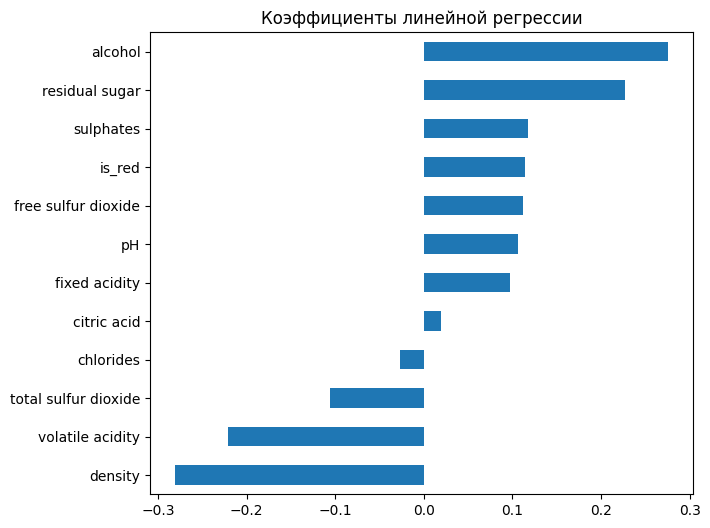

In [ ]:
# lr.coef_ — веса, которые модель выучила
# X.columns — названия признаков
lr_coefs = pd.Series(lr.coef_, index=X.columns).sort_values()
# рисуем горизонтальные столбики
# figsize задаёт размер картинки
lr_coefs.plot.barh(figsize=(7, 6))
plt.title("Коэффициенты линейной регрессии")
plt.show()

**Вывод.** Линейная регрессия лучше baseline (RMSE 0.729 против 0.880), но порог 0.70 **не проходит**.

Признаки масштабируем (`StandardScaler`), потому что они измерены в разных единицах.

Самые большие по модулю веса: `density` (−0.28), `alcohol` (+0.28), `residual sugar` (+0.23), `volatile acidity` (−0.22). Влияние `alcohol` (+) и `volatile acidity` (−) совпадает с EDA. Большие веса у `density` и `residual sugar` нельзя трактовать буквально: эти признаки сильно связаны с алкоголем и между собой (мультиколлинеарность), и модель «делит» влияние между ними.

Линейная модель видит только прямые зависимости. Пороги, «золотую середину» и взаимодействия признаков она описать не может — поэтому и не дотягивает до порога.

## 6. Random Forest

n_estimators=300 cколько деревьев будет в лесу
max_features="sqrt" сколько прищнаков перебирать в каждом узле тут корень из 12
random_state=RANDOM_STATE С фиксированным random_state при перезапуске получится тот же лес и тот же RMSE
n_jobs=-1 Сколько ядер процессора использовать. -1 значит все

In [16]:

rf = RandomForestRegressor(
    n_estimators=300,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

rmse, mae = get_metrics(y_test, y_pred_rf)
results.append(["Random Forest", rmse, mae])
print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}")

RMSE: 0.6798, MAE: 0.5256


rf.feature_importances_ — важность каждого признака, 12 чисел без подписей, в сумме дают 1


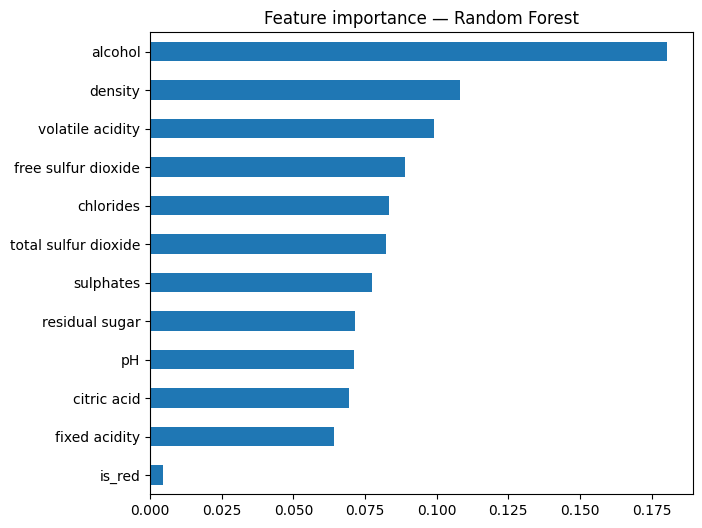

In [17]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
rf_importance.plot.barh(figsize=(7, 6))
plt.title("Feature importance — Random Forest")
plt.show()

**Вывод.** Random Forest даёт RMSE 0.680 — **порог 0.70 пройден**. Самый важный признак — `alcohol`, это совпадает с EDA и с линейной регрессией. На втором месте `density`: в каждом узле доступны только 3 случайных признака, и когда `alcohol` не выпал, дерево берёт `density` — она сильно связана с алкоголем и фактически его заменяет. Дальше `volatile acidity` и `free sulfur dioxide`. Признак `is_red` почти не важен — различия красных и белых вин уже видны через другие признаки состава.

## 7. Gradient Boosting

значения по умолчанию 
n_estimators=100 100 деревьев, то есть 100 шагов исправления
learning_rate=0.1 каждую поправку прибавляем на 10%, маленькими шагами, чтобы не выучить шум
max_depth=3 каждое дерево маленькое, максимум 3 вопроса подряд

In [18]:
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)


в лесу ответы деревьев усредняются, а здесь поправки складываются

In [19]:
rmse, mae = get_metrics(y_test, y_pred_gb)
results.append(["Gradient Boosting", rmse, mae])
print(f"RMSE: {rmse:.4f}, MAE: {mae:.4f}")


RMSE: 0.6943, MAE: 0.5391


насколько каждый признак суммарно уменьшил ошибку во всех узлах всех 100 деревьев

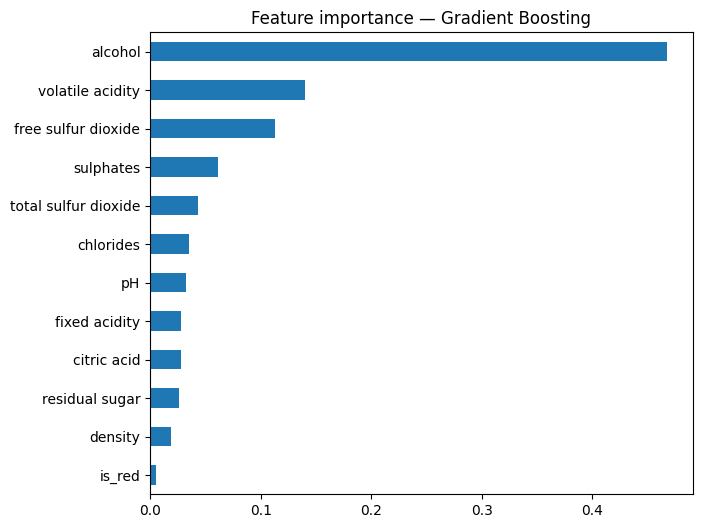

In [20]:
gb_importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values()
gb_importance.plot.barh(figsize=(7, 6))
plt.title("Feature importance — Gradient Boosting")
plt.show()


**Вывод.** Gradient Boosting даёт RMSE 0.694 — порог пройден, но с маленьким запасом. У бустинга `alcohol` забирает почти половину всей важности (≈ 0.47), дальше `volatile acidity` и `free sulfur dioxide`. Первые деревья бустинга исправляют самую большую ошибку и почти всегда используют самый сильный признак, а следующим деревьям остаются мелкие поправки.

## 8. Итоговое сравнение моделей

In [21]:
results_df = pd.DataFrame(results, columns=["Модель", "RMSE", "MAE"])
results_df.round(4)

,Модель,RMSE,MAE
0,Baseline,0.8801,0.6948
1,Linear Regression,0.7292,0.5660
2,Random Forest,0.6798,0.5256
3,Gradient Boosting,0.6943,0.5391


**Вывод.** Все три модели обогнали baseline — значит, они действительно извлекают полезную информацию из признаков. Порог 0.70 проходят Random Forest (0.680) и Gradient Boosting (0.694), лучшая модель — **Random Forest**.

- **Линейная регрессия хуже деревьев**, потому что умеет описывать только прямые зависимости (высокое смещение, bias). В данных о вине есть пороги и нелинейности (например, качество резко падает при высокой летучей кислотности) и взаимодействия признаков — деревья находят их автоматически.
- **Random Forest лучший**: деревья ловят нелинейности, а усреднение 300 разных деревьев убирает нестабильность отдельного дерева (снижает разброс, variance).
- **Gradient Boosting чуть хуже леса**: использовали параметры по умолчанию (всего 100 маленьких деревьев), и бустинг сильнее зависит от настройки параметров, а лес хорошо работает «из коробки».
- У всех моделей **RMSE заметно больше MAE** — значит, есть редкие крупные ошибки. Это видно в анализе ошибок.

Все модели обучались на одном train и оценивались на одном и том же test, поэтому сравнение честное.

## 9. Feature importance: сравнение моделей

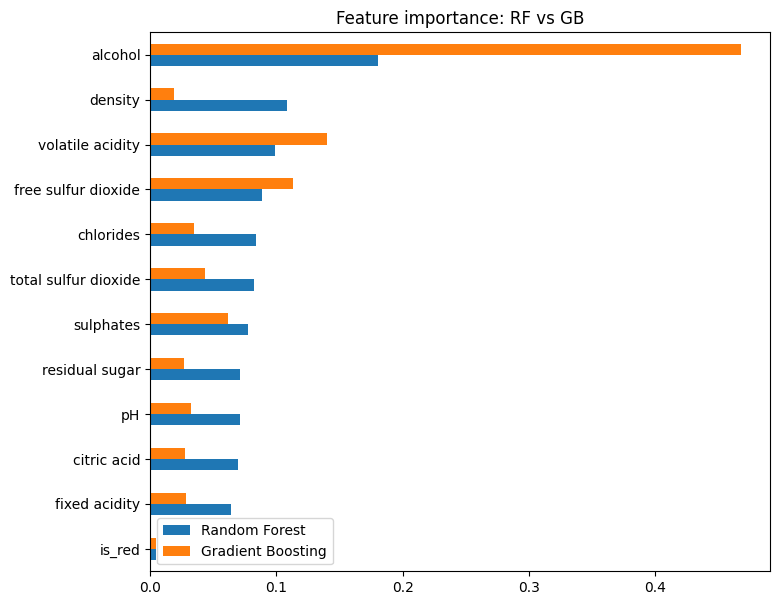

In [22]:
importance_df = pd.DataFrame({
    "Random Forest": rf_importance,
    "Gradient Boosting": gb_importance,
}).sort_values("Random Forest")

importance_df.plot.barh(figsize=(8, 7))
plt.title("Feature importance: RF vs GB")
plt.show()


**Вывод.** У обеих моделей главный признак — **alcohol**, дальше **volatile acidity** и **free sulfur dioxide**. Это согласуется с EDA: alcohol имел самую сильную корреляцию с качеством, volatile acidity — одну из самых сильных отрицательных. Различие моделей: у Gradient Boosting важность сосредоточена на alcohol (≈ 0.47), а у Random Forest распределена ровнее (alcohol ≈ 0.18) — из-за случайного выбора признаков в узлах лес чаще использует другие признаки, особенно `density`, которая дублирует alcohol. В линейной регрессии density тоже получила большой вес — это следствие мультиколлинеарности.

**Можно ли по feature importance утверждать, что изменение признака является причиной изменения качества?** Нет.
1. Важность показывает, что признак **помогает предсказать** оценку, а не что он на неё **влияет**. Модель учится на наблюдениях, а не на эксперименте.
2. Может существовать **скрытая общая причина**: например, спелый виноград даёт и больше спирта, и лучший вкус. Тогда алкоголь и качество растут вместе, но добавление спирта не сделает вино лучше.
3. Признак может быть **заменителем** другого (density важна в лесе, потому что связана с alcohol), а порядок важностей меняется от модели к модели.

Доказать причинность можно только экспериментом, когда меняют один фактор, а остальные фиксируют.

## 10. Анализ ошибок лучшей модели (Random Forest)

Ошибка = правда − прогноз: плюс — модель занизила оценку, минус — завысила.

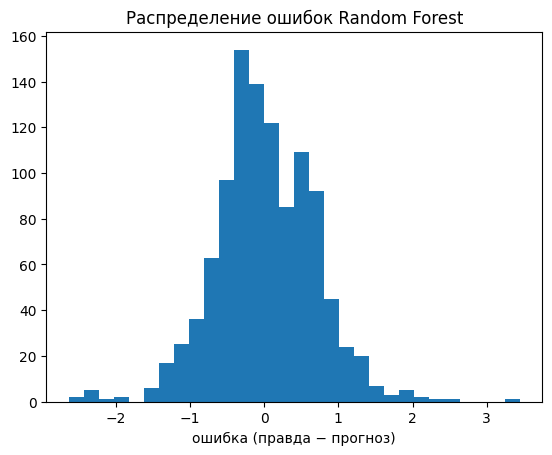

In [23]:
errors = y_test - y_pred_rf

plt.hist(errors, bins=30)
plt.title("Распределение ошибок Random Forest")
plt.xlabel("ошибка (правда − прогноз)")
plt.show()

In [24]:
errors_df = X_test.copy()
errors_df["true"] = y_test
errors_df["pred"] = y_pred_rf.round(2)
errors_df["error"] = errors.round(2)
errors_df["abs_error"] = errors.abs()

# 10 вин с самыми большими ошибками
worst = errors_df.sort_values("abs_error", ascending=False).head(10)
worst[["true", "pred", "error", "alcohol", "volatile acidity", "sulphates", "is_red"]]

,true,pred,error,alcohol,volatile acidity,sulphates,is_red
2012,9,5.56,3.44,10.4,0.270,0.46,0
1982,3,5.63,-2.63,12.6,0.390,0.37,0
1571,3,5.53,-2.53,9.8,0.260,0.50,0
2549,8,5.52,2.48,10.5,0.220,0.38,0
2783,3,5.42,-2.42,9.4,0.250,0.63,0
4984,4,6.41,-2.41,11.5,0.260,0.38,0
1165,3,5.38,-2.38,9.8,0.815,0.51,1
3881,8,5.70,2.30,12.5,0.530,0.50,0
4158,4,6.29,-2.29,12.9,0.640,0.60,0
1245,3,5.27,-2.27,9.7,0.980,0.55,1


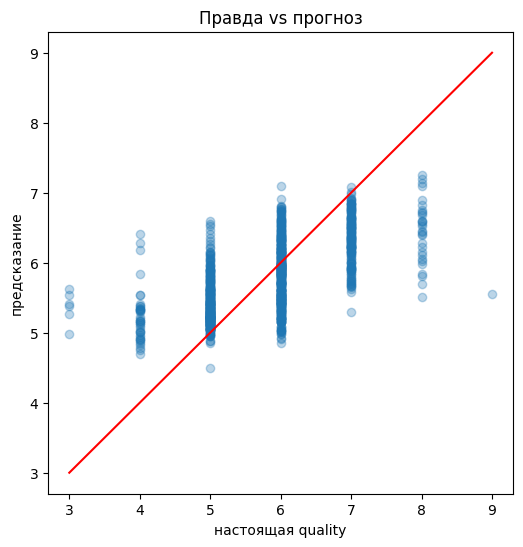

In [25]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.plot([3, 9], [3, 9], color="red")   # идеальная линия: прогноз = правда
plt.xlabel("настоящая quality")
plt.ylabel("предсказание")
plt.title("Правда vs прогноз")
plt.show()

In [26]:
# средние значения главных признаков для каждой оценки — для сравнения с худшими винами
df.groupby("quality")[["alcohol", "volatile acidity"]].mean().round(2)

,alcohol,volatile acidity
quality,,
3,10.22,0.52
4,10.22,0.46
5,9.87,0.39
6,10.65,0.32
7,11.51,0.29
8,11.91,0.30
9,12.18,0.30


In [27]:
# ошибки для каждой настоящей оценки
errors_df.groupby("true").agg(
    count=("error", "size"),
    mae=("abs_error", "mean"),
    mean_error=("error", "mean"),
).round(2)

,count,mae,mean_error
true,,,
3,6,2.37,-2.37
4,41,1.23,-1.23
5,350,0.43,-0.43
6,465,0.39,0.16
7,171,0.67,0.66
8,30,1.55,1.55
9,1,3.44,3.44


**Вывод.**
- Ошибки в среднем около нуля (систематического сдвига нет), больше половины вин предсказаны с ошибкой меньше 0.5 балла, но примерно у 12% вин ошибка больше 1 балла — это и есть редкие крупные промахи, из-за которых RMSE (0.68) заметно больше MAE (0.53).
- Модель работает **неодинаково для разных оценок**: на 5 и 6 средняя ошибка около 0.4, а на краях — 1.2–2.4 балла для оценок 3–4 и 1.5–3.4 для 8–9.
- Направление ошибок: **низкие оценки модель завышает, высокие — занижает**, прогнозы тянутся к середине. Все предсказания лежат примерно в диапазоне 4.5–7.3 — модель ни разу не поставила 3 или 9. На графике «правда vs прогноз» облако точек более пологое, чем красная линия.

**Разбор худших вин.**
- Вино с оценкой **9**, прогноз 5.56: алкоголь 10.4 — как у обычного вина (в среднем у девяток 12.2, у пятёрок 9.9). По составу оно ничем не выделяется, и модель поставила ему среднюю оценку.
- Вино с оценкой **3**, прогноз 5.63: алкоголь 12.6 — как у хороших вин. Состав «обманчивый», а причина низкой оценки, видимо, в том, чего нет в данных (аромат, дефект, сорт винограда).
- Красное вино с оценкой **3** и очень высокой летучей кислотностью (0.815): модель правильно сдвинула прогноз вниз, но только до 5.38 — из-за редкости троек она не решается поставить такую низкую оценку.

**Почему модель хуже предсказывает редкие значения quality.** Таких вин очень мало (в тесте 6 троек и одна девятка), поэтому в листьях деревьев они оказываются вместе с винами 5–7, и среднее листа получается «средним». Модель обучается минимизировать квадратичную ошибку, и ей выгоднее предсказывать значения ближе к среднему; лес дополнительно усредняет 300 деревьев, что ещё сильнее сглаживает крайние значения. Кроме того, оценки ставят люди (субъективность и шум в разметке), и в данных нет многих факторов, влияющих на оценку.

## 11. Общий вывод

Лучшая модель — **Random Forest** с RMSE ≈ 0.680 и MAE ≈ 0.526: порог 0.70 пройден, результат заметно лучше baseline (0.880). Модели на основе деревьев обошли линейную регрессию, потому что учитывают нелинейные зависимости и взаимодействия признаков. Главные признаки — `alcohol`, `volatile acidity` и `free sulfur dioxide`, что согласуется с первичным анализом, но не означает причинной связи. Слабое место всех моделей — редкие оценки (3, 4, 8, 9): из-за малого числа примеров прогнозы стягиваются к средним значениям 5–6.